# Step 1 — Data Cleaning & Leak-Free Split
**Oral Diseases Image Classification · Sprint Two (CNN & Computer Vision)**

What this notebook does:
1. Finds the **original** images only (skips the `augmented/preview` folders and the YOLO folder).
2. Removes **exact duplicates** (MD5) and images that appear under **more than one class** (conflicting labels).
3. Finds **near-duplicates** with perceptual hashing (pHash). Near-duplicates are kept but forced into the **same split**, so a copy of a training image can never end up in validation/test.
4. Splits 70 / 15 / 15 (stratified by class, grouped by near-duplicate group).
5. Saves the clean dataset as `train / val / test / <class>/` folders + a `manifest.csv`.

**Before running:** right-side panel → *Add Input* → add the Oral Diseases dataset. Turn **Internet off/on** — no internet is needed here.

In [1]:
import os, json, shutil, hashlib, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.fft import dctn
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from tqdm.auto import tqdm

SEED     = 42
NEAR_T   = 4          # pHash Hamming distance (out of 64) to call two images near-duplicates
DATA_ROOT = os.environ.get("DATA_ROOT", "/kaggle/input")
OUT_DIR   = os.environ.get("OUT_DIR",   "/kaggle/working/oral_clean")

random.seed(SEED); np.random.seed(SEED)
print("DATA_ROOT:", DATA_ROOT)
print("OUT_DIR  :", OUT_DIR)

DATA_ROOT: /kaggle/input
OUT_DIR  : /kaggle/working/oral_clean


## 1) Find the original images and assign each folder to a class

In [2]:
KEYWORDS = {"calculus": "Calculus", "gingivitis": "Gingivitis", "hypodontia": "Hypodontia",
            "caries": "Caries", "ulcer": "Mouth_Ulcer", "discoloration": "Discoloration"}
SKIP_WORDS = ("augment", "preview", "yolo")           # pre-augmented copies + detection dataset
IMG_EXT = (".jpg", ".jpeg", ".png")

rows, skipped = [], {}
for d, _, files in os.walk(DATA_ROOT):
    imgs = [f for f in files if f.lower().endswith(IMG_EXT)]
    if not imgs:
        continue
    rel = os.path.relpath(d, DATA_ROOT)
    parts = rel.split(os.sep)
    if DATA_ROOT.rstrip("/") == "/kaggle/input":
        parts = parts[1:]                              # ignore the dataset slug name itself
    rel_low = "/".join(parts).lower()
    if any(w in rel_low for w in SKIP_WORDS):
        skipped[rel] = len(imgs); continue
    classes = [v for k, v in KEYWORDS.items() if k in rel_low]
    if len(classes) != 1:
        skipped[rel + "  (ambiguous class)"] = len(imgs); continue
    rows += [(os.path.join(d, f), classes[0], rel) for f in imgs]

raw = pd.DataFrame(rows, columns=["path", "label", "folder"]).sort_values("path").reset_index(drop=True)
assert raw.label.nunique() == 6, f"Expected 6 classes, found {raw.label.nunique()} - check DATA_ROOT"

print("USED folders:")
print(raw.groupby(["label", "folder"]).size().to_string())
print("\nSKIPPED folders (augmented / yolo):")
for k, v in skipped.items(): print(f"  {v:5d}  {k}")
print(f"\nTotal original images: {len(raw)}   (expected 5563 for the Kaggle dataset)")

USED folders:
label          folder                                                                                                                                                 
Calculus       datasets/salmansajid05/oral-diseases/Calculus/Calculus                                                                                                     1296
Caries         datasets/salmansajid05/oral-diseases/Data caries/Data caries/caries orignal data set/done                                                                   219
Discoloration  datasets/salmansajid05/oral-diseases/Tooth Discoloration/Tooth Discoloration /tooth discoloration original dataset/tooth discoloration original dataset     183
Gingivitis     datasets/salmansajid05/oral-diseases/Gingivitis/Gingivitis                                                                                                 2349
Hypodontia     datasets/salmansajid05/oral-diseases/hypodontia/hypodontia                                              

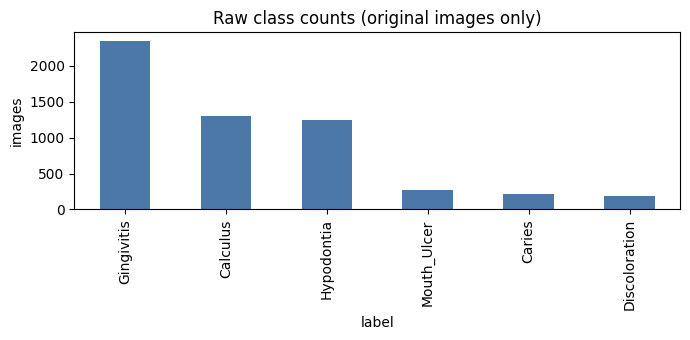

In [3]:
raw.label.value_counts().plot.bar(color="#4C78A8", figsize=(7,3.5), title="Raw class counts (original images only)")
plt.ylabel("images"); plt.tight_layout(); plt.show()

## 2) Hash every image (MD5 + perceptual hash)

In [4]:
def phash64(img):
    g = img.convert("L").resize((32, 32), Image.LANCZOS)
    d = dctn(np.asarray(g, dtype=np.float32), norm="ortho")[:8, :8].flatten()
    return d > np.median(d[1:])                         # 64 bits

md5s, hashes, sizes, ok = [], [], [], []
for p in tqdm(raw.path):
    try:
        with open(p, "rb") as f: md5s.append(hashlib.md5(f.read()).hexdigest())
        with Image.open(p) as im:
            im.load(); sizes.append(im.size); hashes.append(phash64(im)); ok.append(True)
    except Exception as e:
        md5s.append(None); sizes.append((0, 0)); hashes.append(np.zeros(64, bool)); ok.append(False)

raw["md5"] = md5s
raw["w"] = [s[0] for s in sizes]; raw["h"] = [s[1] for s in sizes]
raw["ok"] = ok
PH = np.array(hashes, dtype=np.float32)
print("Unreadable images:", (~raw.ok).sum())

  0%|          | 0/5563 [00:00<?, ?it/s]

Unreadable images: 0


## 3) Clean: exact duplicates, then cross-class conflicts

In [5]:
funnel = [("Raw original images", len(raw))]

df = raw[raw.ok].copy();                                  funnel.append(("Readable images", len(df)))

# 3a) the same file content under more than one class -> label is ambiguous -> drop ALL copies
n_cls = df.groupby("md5").label.nunique()
conflict_md5 = n_cls[n_cls > 1].index
n_conflict = df.md5.isin(conflict_md5).sum()
df = df[~df.md5.isin(conflict_md5)];                      funnel.append((f"After dropping cross-class exact duplicates (-{n_conflict})", len(df)))

# 3b) same content twice in the same class -> keep one
df = df.drop_duplicates("md5");                           funnel.append(("After dropping exact duplicates inside a class", len(df)))

print(pd.DataFrame(funnel, columns=["step", "images"]).to_string(index=False))
print()
print(df.label.value_counts().to_string())

                                               step  images
                                Raw original images    5563
                                    Readable images    5563
After dropping cross-class exact duplicates (-1510)    4053
     After dropping exact duplicates inside a class    3507

label
Gingivitis       1236
Hypodontia       1215
Calculus          449
Mouth_Ulcer       243
Caries            191
Discoloration     173


## 4) Near-duplicates (pHash)
Exact hashing misses re-saved / resized / slightly edited copies. We compare pHash fingerprints:
- Two images with different labels that look the same → **conflicting labels → drop both**.
- Images that look the same and share a label → **kept, but grouped** so they always land in the same split.

In [6]:
H = PH[df.index.values]                                   # fingerprints of the surviving images
labels = df.label.values
n = len(H)

D = 64 - (H @ H.T + (1 - H) @ (1 - H).T)                  # Hamming distance matrix (n x n)
np.fill_diagonal(D, 64)
ii, jj = np.where(np.triu(D <= NEAR_T, 1))
print(f"Near-duplicate pairs (distance <= {NEAR_T}): {len(ii)}")

# near-duplicates with DIFFERENT labels -> drop both images
cross = labels[ii] != labels[jj]
drop_local = set(ii[cross]) | set(jj[cross])
print(f"Cross-class near-duplicate pairs: {cross.sum()}  -> dropping {len(drop_local)} images")

keep_mask = np.ones(n, bool); keep_mask[list(drop_local)] = False
df = df[keep_mask].copy()
H = H[keep_mask]; labels = labels[keep_mask]; n = len(df)

# connected components of the near-duplicate graph = groups
D = 64 - (H @ H.T + (1 - H) @ (1 - H).T); np.fill_diagonal(D, 64)
ii, jj = np.where(np.triu(D <= NEAR_T, 1))
adj = coo_matrix((np.ones(len(ii)), (ii, jj)), shape=(n, n))
n_groups, group_id = connected_components(adj, directed=False)
df["group"] = group_id

sizes = pd.Series(group_id).value_counts()
print(f"\nFinal clean images: {n}")
print(f"Near-duplicate groups: {n_groups}  | groups with >1 image: {(sizes>1).sum()}  | largest group: {sizes.max()}")

Near-duplicate pairs (distance <= 4): 1702
Cross-class near-duplicate pairs: 8  -> dropping 6 images

Final clean images: 3501
Near-duplicate groups: 2520  | groups with >1 image: 386  | largest group: 8


## 5) Stratified, group-aware split — 70 / 15 / 15

In [7]:
df = df.reset_index(drop=True)
y, g = df.label.values, df.group.values

# test ~ 1/7 (14.3%)
sk1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
rest_idx, test_idx = next(sk1.split(df, y, g))
# val ~ 1/6 of the rest  (~14.3% of the total)
rest = df.iloc[rest_idx]
sk2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
tr_i, va_i = next(sk2.split(rest, rest.label.values, rest.group.values))

df["split"] = ""
df.loc[rest.index[tr_i], "split"] = "train"
df.loc[rest.index[va_i], "split"] = "val"
df.loc[test_idx,         "split"] = "test"

# ---- safety checks: nothing may leak between splits ----
assert (df.split != "").all()
assert df.groupby("group").split.nunique().max() == 1, "a near-duplicate group is split across sets!"
assert df.groupby("md5").split.nunique().max() == 1,   "an exact duplicate is split across sets!"
print("Leak checks passed: no near-duplicate group and no identical file crosses train/val/test.\n")

tab = pd.crosstab(df.label, df.split)[["train", "val", "test"]]
tab["total"] = tab.sum(axis=1)
tab.loc["TOTAL"] = tab.sum()
print(tab.to_string())
print("\nSplit ratio:", (df.split.value_counts(normalize=True).round(3)).to_dict())

Leak checks passed: no near-duplicate group and no identical file crosses train/val/test.

split          train  val  test  total
label                                 
Calculus         323   62    60    445
Caries           134   29    28    191
Discoloration    124   24    23    171
Gingivitis       876  177   183   1236
Hypodontia       865  170   180   1215
Mouth_Ulcer      175   36    32    243
TOTAL           2497  498   506   3501

Split ratio: {'train': 0.713, 'test': 0.145, 'val': 0.142}


## 6) Save the clean dataset

In [8]:
if os.path.exists(OUT_DIR): shutil.rmtree(OUT_DIR)
paths = []
for _, r in tqdm(df.iterrows(), total=len(df)):
    ext = os.path.splitext(r.path)[1].lower()
    dst_dir = os.path.join(OUT_DIR, r.split, r.label); os.makedirs(dst_dir, exist_ok=True)
    dst = os.path.join(dst_dir, f"{r.md5[:12]}{ext}")
    shutil.copy2(r.path, dst); paths.append(dst)
df["clean_path"] = paths

class_names = sorted(df.label.unique())
df[["clean_path", "label", "split", "group", "md5", "w", "h"]].to_csv(os.path.join(OUT_DIR, "manifest.csv"), index=False)
json.dump({"class_names": class_names, "seed": SEED, "near_dup_threshold": NEAR_T},
          open(os.path.join(OUT_DIR, "meta.json"), "w"), indent=2)
print("Classes:", class_names)
print("Saved to:", OUT_DIR)
for s in ("train", "val", "test"):
    print(s, sum(len(fs) for _, _, fs in os.walk(os.path.join(OUT_DIR, s))), "images")

  0%|          | 0/3501 [00:00<?, ?it/s]

Classes: ['Calculus', 'Caries', 'Discoloration', 'Gingivitis', 'Hypodontia', 'Mouth_Ulcer']
Saved to: /kaggle/working/oral_clean
train 2497 images
val 498 images
test 506 images


## 7) Quick visual check

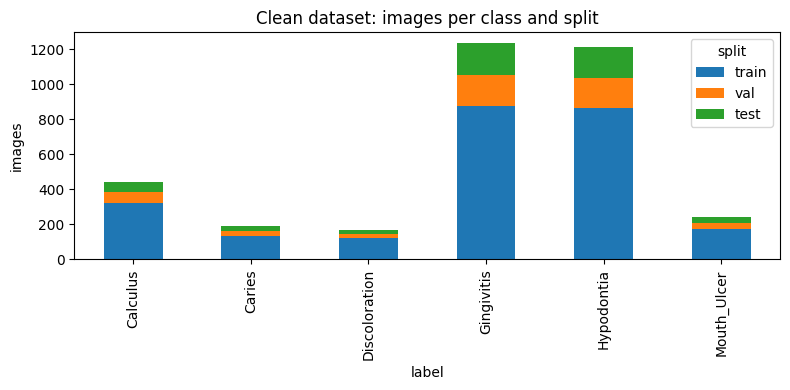

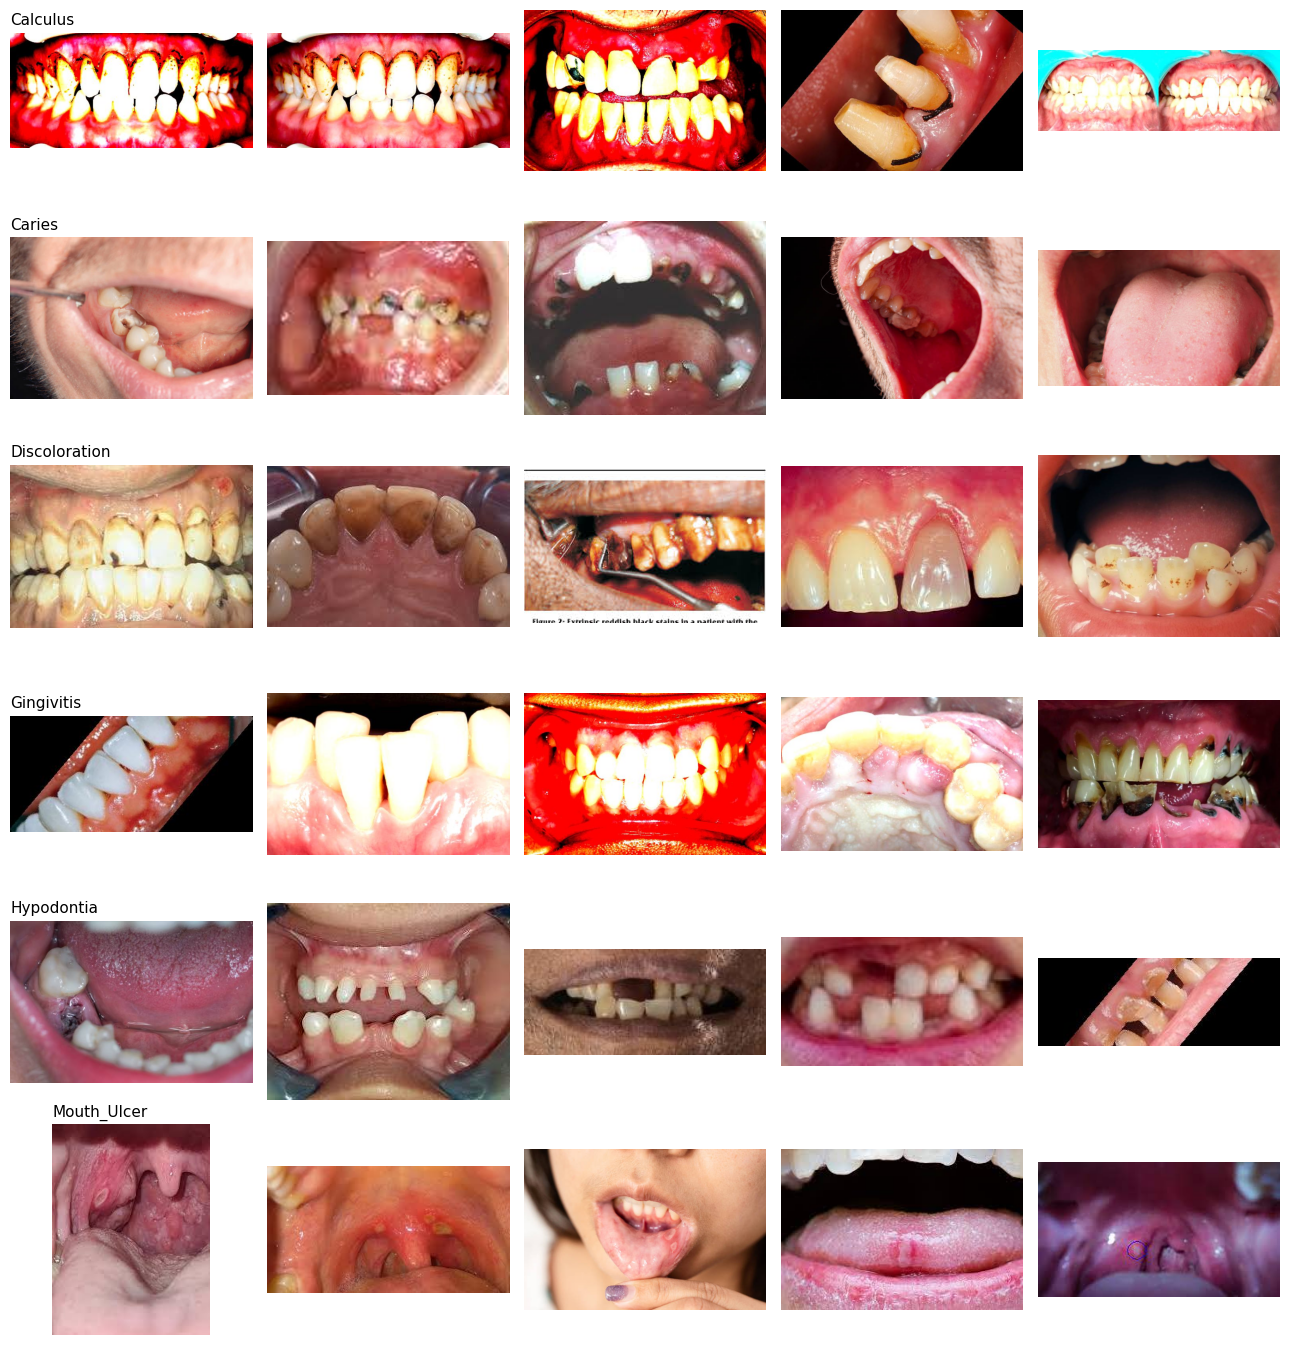

In [9]:
ct = pd.crosstab(df.label, df.split)[["train", "val", "test"]]
ct.plot.bar(stacked=True, figsize=(8,4), title="Clean dataset: images per class and split")
plt.ylabel("images"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(len(class_names), 5, figsize=(13, 2.3*len(class_names)))
for r, c in enumerate(class_names):
    sample = df[(df.label == c) & (df.split == "train")].sample(5, random_state=SEED)
    for k, p in enumerate(sample.clean_path):
        axes[r, k].imshow(Image.open(p).convert("RGB")); axes[r, k].axis("off")
    axes[r, 0].set_title(c, loc="left", fontsize=11)
plt.tight_layout(); plt.show()

In [10]:
print("Image size summary (width x height) of the clean set:")
print(df[["w", "h"]].describe().loc[["min", "50%", "max"]].round(0).to_string())

Image size summary (width x height) of the clean set:
         w      h
min  121.0   33.0
50%  612.0  263.0
max  685.0  612.0
